Milestone One summary notebook, Mike Hembree

This one puts every technique from Weeks 1 through 6 on the same footing so the numbers in the milestone paper can be compared. Regression models (Weeks 1 to 3) predict ICU length of stay with five fold cross validation repeated six times on all 140 stays. Classification models (Weeks 4 to 6) predict a positive delirium screen with stratified five fold cross validation repeated three times, and any model that gets tuned is tuned inside each training fold (nested), so the reported scores never touch the tuning data. Data is the MIMIC-IV Clinical Database Demo, 140 ICU stays.

In [1]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.model_selection import train_test_split, RepeatedKFold, RepeatedStratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, roc_auc_score, roc_curve, f1_score, recall_score, precision_score, accuracy_score, confusion_matrix

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.family'] = 'serif'


In [2]:
# load the feature table and fill the few missing values with the median
feat = pd.read_csv('delirium_features.csv')

rcols = ['anchor_age', 'gender', 'heart_rate', 'sbp', 'dbp', 'resp_rate', 'temp_f', 'spo2', 'gcs_total_min', 'delirium_positive']
ccols = rcols[:-1]

data = feat[rcols + ['los']].copy()
for c in rcols:
    data[c] = data[c].fillna(data[c].median())

X = data[rcols]
y = data['los']
Xc = data[ccols]
yc = feat['delirium_positive'].fillna(0).astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size = 0.2, random_state = 42, stratify = yc)

cv_reg = RepeatedKFold(n_splits = 5, n_repeats = 6, random_state = 1)
cv_clf = RepeatedStratifiedKFold(n_splits = 5, n_repeats = 3, random_state = 1)
print(data.shape, yc.value_counts().to_dict())


(140, 11) {0: 95, 1: 45}


In [3]:
# regression comparison, weeks 1 to 3, same repeated cv for everything
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.preprocessing import PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.feature_selection import SequentialFeatureSelector

w3 = pd.read_csv('figs/wk3_results.csv')
best3 = w3.loc[w3.groupby('method')['cv rmse'].idxmin()].set_index('method')['k'].to_dict()
print(best3)

reg_models = {
    'linear (baseline)': make_pipeline(StandardScaler(), LinearRegression()),
    'week 1 interactions only': make_pipeline(StandardScaler(), PolynomialFeatures(2, interaction_only = True, include_bias = False), LinearRegression()),
    'week 1 degree 2': make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias = False), LinearRegression()),
    'week 2 ridge': make_pipeline(StandardScaler(), RidgeCV(alphas = np.logspace(-3, 3, 50))),
    'week 2 lasso': make_pipeline(StandardScaler(), LassoCV(alphas = np.logspace(-3, 1, 50), max_iter = 10000)),
    'week 2 elastic net': make_pipeline(StandardScaler(), ElasticNetCV(alphas = np.logspace(-3, 1, 50), l1_ratio = [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99, 1], max_iter = 10000)),
    'week 3 forward selection': make_pipeline(StandardScaler(), SequentialFeatureSelector(LinearRegression(), n_features_to_select = int(best3['forward selection']), direction = 'forward', cv = 5), LinearRegression()),
    'week 3 backward selection': make_pipeline(StandardScaler(), SequentialFeatureSelector(LinearRegression(), n_features_to_select = int(best3['backward selection']), direction = 'backward', cv = 5), LinearRegression()),
    'week 3 pcr': make_pipeline(StandardScaler(), PCA(int(best3['pcr'])), LinearRegression()),
    'week 3 plsr': make_pipeline(StandardScaler(), PLSRegression(int(best3['plsr']))),
}
rows = []
for name, m in reg_models.items():
    r = cross_validate(m, X, y, cv = cv_reg, scoring = ('r2', 'neg_root_mean_squared_error'), return_train_score = True, n_jobs = 2)
    rows.append({'model': name, 'train r2': r['train_r2'].mean(), 'cv r2': r['test_r2'].mean(), 'cv rmse': -r['test_neg_root_mean_squared_error'].mean(), 'rmse sd': r['test_neg_root_mean_squared_error'].std()})
reg_tab = pd.DataFrame(rows)
reg_tab.to_csv('figs/regression_summary.csv', index = False)
reg_tab.round(3)


{'all ten predictors': 10, 'backward selection': 1, 'forward selection': 1, 'pcr': 5, 'plsr': 1}


,model,train r2,cv r2,cv rmse,rmse sd
0,linear (baseline),0.399,0.151,3.350,0.748
1,week 1 interactions only,0.783,-1.059,4.625,1.163
2,week 1 degree 2,0.813,-3.622,6.036,3.080
3,week 2 ridge,0.374,0.214,3.275,0.772
4,week 2 lasso,0.377,0.242,3.217,0.759
5,week 2 elastic net,0.374,0.238,3.228,0.776
6,week 3 forward selection,0.291,0.226,3.262,0.761
7,week 3 backward selection,0.291,0.226,3.262,0.761
8,week 3 pcr,0.362,0.241,3.214,0.737
9,week 3 plsr,0.374,0.235,3.215,0.711


Every regularized, selected, or reduced model has a cv r squared between 0.21 and 0.24 and the plain linear model is at 0.15, while the polynomial expansions are way below zero. Lasso is nominally best at 0.242 but pcr (0.241) and plsr (0.235) are essentially the same.

In [4]:
# week 2 depth, cv rmse across the alpha grid for ridge and lasso, plus the lasso path
from sklearn.linear_model import Ridge, Lasso, lasso_path
alphas = np.logspace(-2, 2, 30)
ridge_curve = []
lasso_curve = []
for a in alphas:
    ridge_curve.append(-cross_validate(make_pipeline(StandardScaler(), Ridge(alpha = a)), X, y, cv = cv_reg, scoring = 'neg_root_mean_squared_error', n_jobs = 2)['test_score'].mean())
    lasso_curve.append(-cross_validate(make_pipeline(StandardScaler(), Lasso(alpha = a, max_iter = 10000)), X, y, cv = cv_reg, scoring = 'neg_root_mean_squared_error', n_jobs = 2)['test_score'].mean())
lin_rmse = reg_tab.loc[0, 'cv rmse']
print('ridge best:', alphas[int(np.argmin(ridge_curve))], round(min(ridge_curve), 3))
print('lasso best:', alphas[int(np.argmin(lasso_curve))], round(min(lasso_curve), 3))
print('linear:', round(lin_rmse, 3))


ridge best: 52.98316906283707 3.246
lasso best: 0.32903445623126676 3.196
linear: 3.35


In [5]:
# lasso coefficients across alpha on the full data
Xs = StandardScaler().fit_transform(X)
la, coefs, _ = lasso_path(Xs, y, alphas = alphas[::-1])
nz = pd.DataFrame(coefs.T, index = la, columns = rcols)
print((nz.abs() > 1e-8).sum(axis = 1).iloc[::3])
at = nz.iloc[np.argmin(np.abs(la - alphas[int(np.argmin(lasso_curve))]))]
print(at.round(3))


100.000000    0
38.566204     0
14.873521     0
5.736153      0
2.212216      0
0.853168      2
0.329034      5
0.126896      6
0.048939      7
0.018874      8
dtype: int64
anchor_age          -0.000
gender              -0.000
heart_rate           0.117
sbp                 -0.204
dbp                 -0.000
resp_rate            0.000
temp_f               0.121
spo2                -0.000
gcs_total_min       -0.697
delirium_positive    1.457
Name: 0.32903445623126676, dtype: float64


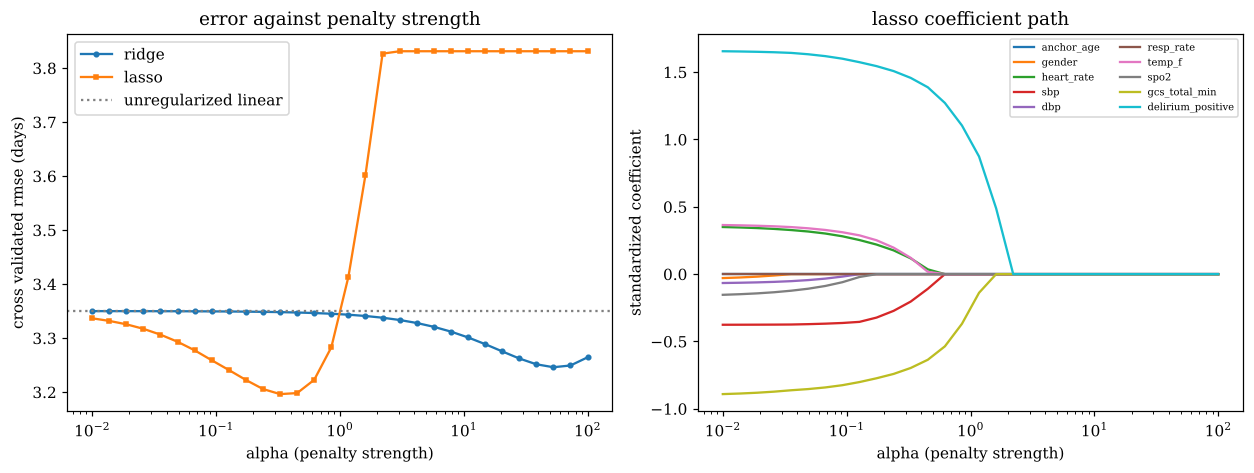

In [6]:
# figure, regularization depth
fig, ax = plt.subplots(1, 2, figsize = (11.5, 4.4))
ax[0].plot(alphas, ridge_curve, 'o-', label = 'ridge', markersize = 3)
ax[0].plot(alphas, lasso_curve, 's-', label = 'lasso', markersize = 3)
ax[0].axhline(lin_rmse, color = 'gray', linestyle = ':', label = 'unregularized linear')
ax[0].set_xscale('log')
ax[0].set_xlabel('alpha (penalty strength)')
ax[0].set_ylabel('cross validated rmse (days)')
ax[0].set_title('error against penalty strength')
ax[0].legend()
for c in rcols:
    ax[1].plot(la, nz[c], label = c)
ax[1].set_xscale('log')
ax[1].set_xlabel('alpha (penalty strength)')
ax[1].set_ylabel('standardized coefficient')
ax[1].set_title('lasso coefficient path')
ax[1].legend(fontsize = 6.5, ncol = 2)
plt.tight_layout()
plt.savefig('figs/regularization.png', dpi = 200)
plt.show()


Left panel, lasso reaches its lowest error (about 3.20) near alpha of 0.33 and falls apart past about 1, where the penalty zeroes every coefficient and the model just predicts the mean. Ridge barely moves, best around alpha 53 at 3.25. The lasso path on the right shows the delirium flag surviving until the very end, and gcs_total_min is the second last. Note the 3.196 here is the best point on the grid so it's a little optimistic, the 3.217 in the table above, where lasso chose its own alpha inside each fold, is the fair number.

In [7]:
# classification comparison, weeks 4 to 6, tuned models are tuned inside each fold
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

rf_grid = {'max_depth': [3, 5, None], 'min_samples_leaf': [1, 3, 5], 'max_features': ['sqrt', 0.5]}
clf_models = {
    'week 4 logistic, unscaled': LogisticRegression(max_iter = 5000),
    'week 4 logistic, scaled': make_pipeline(StandardScaler(), LogisticRegression(max_iter = 5000)),
    'week 4 logistic, cv regularized': make_pipeline(StandardScaler(), LogisticRegressionCV(Cs = np.logspace(-3, 3, 20), cv = 5, scoring = 'roc_auc', max_iter = 5000)),
    'week 4 logistic, cv balanced': make_pipeline(StandardScaler(), LogisticRegressionCV(Cs = np.logspace(-3, 3, 20), cv = 5, scoring = 'roc_auc', max_iter = 5000, class_weight = 'balanced')),
    'week 5 linear svm, tuned': GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel = 'linear', class_weight = 'balanced')), {'svc__C': [0.001, 0.01, 0.1, 1, 10]}, scoring = 'roc_auc', cv = 5),
    'week 5 rbf svm, tuned': GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel = 'rbf', class_weight = 'balanced')), {'svc__C': [0.1, 1, 10, 100], 'svc__gamma': [0.001, 0.01, 0.03, 0.1, 0.3]}, scoring = 'roc_auc', cv = 5),
    'week 6 decision tree, tuned': GridSearchCV(DecisionTreeClassifier(class_weight = 'balanced', random_state = 0), {'max_depth': [2, 3, 4, 5, 6], 'min_samples_leaf': [1, 3, 5, 10]}, scoring = 'roc_auc', cv = 5),
    'week 6 random forest, default': RandomForestClassifier(n_estimators = 300, random_state = 0),
    'week 6 random forest, tuned': GridSearchCV(RandomForestClassifier(n_estimators = 300, class_weight = 'balanced', random_state = 0), rf_grid, scoring = 'roc_auc', cv = 5),
}
scoring = ('roc_auc', 'recall', 'precision', 'f1', 'accuracy')
rows = []
for name, m in clf_models.items():
    r = cross_validate(m, Xc, yc, cv = cv_clf, scoring = scoring, n_jobs = 2)
    rows.append({'model': name, 'auc': r['test_roc_auc'].mean(), 'auc sd': r['test_roc_auc'].std(), 'recall': r['test_recall'].mean(), 'precision': r['test_precision'].mean(), 'f1': r['test_f1'].mean(), 'accuracy': r['test_accuracy'].mean()})
clf_tab = pd.DataFrame(rows)
clf_tab.to_csv('figs/classification_summary.csv', index = False)
clf_tab.round(3)


,model,auc,auc sd,recall,precision,f1,accuracy
0,"week 4 logistic, unscaled",0.751,0.089,0.481,0.594,0.508,0.721
1,"week 4 logistic, scaled",0.755,0.089,0.481,0.617,0.513,0.724
2,"week 4 logistic, cv regularized",0.750,0.088,0.311,0.529,0.365,0.707
3,"week 4 logistic, cv balanced",0.750,0.086,0.726,0.558,0.621,0.721
4,"week 5 linear svm, tuned",0.745,0.068,0.763,0.527,0.610,0.683
5,"week 5 rbf svm, tuned",0.754,0.073,0.867,0.510,0.625,0.638
6,"week 6 decision tree, tuned",0.753,0.083,0.763,0.539,0.622,0.700
7,"week 6 random forest, default",0.779,0.106,0.519,0.650,0.563,0.743
8,"week 6 random forest, tuned",0.793,0.089,0.763,0.514,0.609,0.693


Almost every classifier lands between 0.745 and 0.755 auc, and the main differences are in recall. Scaling doesn't change the cv auc for logistic regression (0.751 unscaled and 0.755 scaled), the auc jump in Week 4 came from the unscaled model hitting the 100 iteration cap in one split. The random forests are ahead at 0.779 (default) and 0.793 (tuned).

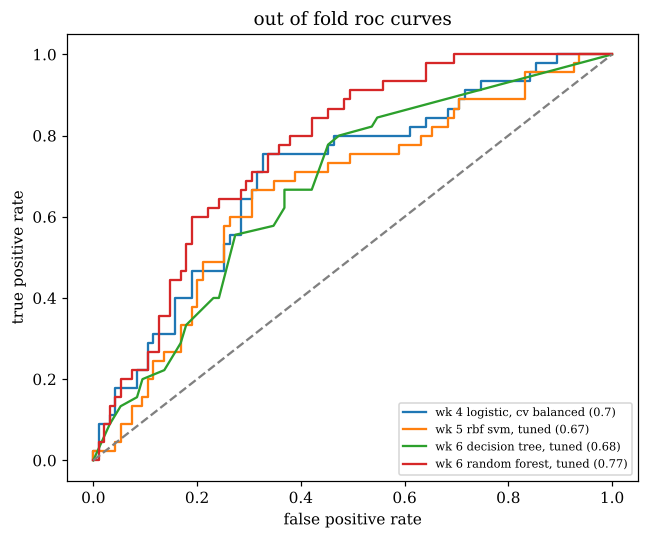

In [8]:
# pooled out of fold roc curves for one model from each classification week
from sklearn.model_selection import StratifiedKFold
picks = ['week 4 logistic, cv balanced', 'week 5 rbf svm, tuned', 'week 6 decision tree, tuned', 'week 6 random forest, tuned']
fig, ax = plt.subplots(figsize = (6, 5))
for nm in picks:
    m = clf_models[nm]
    out = cross_val_predict(m, Xc, yc, cv = StratifiedKFold(5, shuffle = True, random_state = 7), method = 'decision_function' if 'svm' in nm or 'logistic' in nm else 'predict_proba')
    if out.ndim == 2:
        out = out[:, 1]
    fpr, tpr, _ = roc_curve(yc, out)
    ax.plot(fpr, tpr, label = nm.replace('week ', 'wk ') + ' (' + str(round(roc_auc_score(yc, out), 2)) + ')')
ax.plot([0, 1], [0, 1], linestyle = '--', color = 'gray')
ax.set_xlabel('false positive rate')
ax.set_ylabel('true positive rate')
ax.set_title('out of fold roc curves')
ax.legend(fontsize = 7.5, loc = 'lower right')
plt.tight_layout()
plt.savefig('figs/roc_all.png', dpi = 200)
plt.show()


These curves pool the out of fold scores from a single 5 fold split, which is why the aucs shown (0.70, 0.67, 0.68, 0.77) are lower than the per fold averages in the table. The ordering matches though, the forest is above the others through most of the curve.

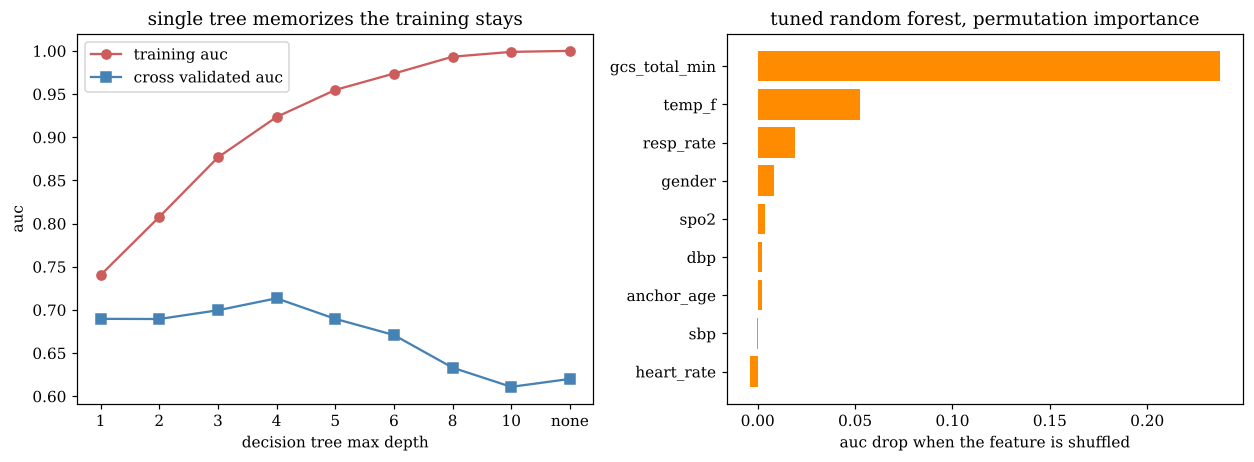

,depth,train,cv
0,1,0.740,0.690
1,2,0.808,0.689
2,3,0.877,0.700
3,4,0.923,0.713
4,5,0.955,0.690
5,6,0.974,0.671
6,8,0.993,0.633
7,10,0.999,0.611
8,none,1.000,0.620


In [9]:
# figure, random forest depth, tree overfitting curve next to feature importance
td = pd.DataFrame({'depth': ['1', '2', '3', '4', '5', '6', '8', '10', 'none']})
rows = []
for d in [1, 2, 3, 4, 5, 6, 8, 10, None]:
    r = cross_validate(DecisionTreeClassifier(max_depth = d, class_weight = 'balanced', random_state = 0), Xc, yc, cv = cv_clf, scoring = 'roc_auc', return_train_score = True, n_jobs = 2)
    rows.append((r['train_score'].mean(), r['test_score'].mean()))
td['train'] = [a for a, b in rows]
td['cv'] = [b for a, b in rows]
imp = pd.read_csv('figs/rf_importance.csv', index_col = 0)
fig, ax = plt.subplots(1, 2, figsize = (11.5, 4.3))
ax[0].plot(td['depth'], td['train'], 'o-', color = 'indianred', label = 'training auc')
ax[0].plot(td['depth'], td['cv'], 's-', color = 'steelblue', label = 'cross validated auc')
ax[0].set_xlabel('decision tree max depth')
ax[0].set_ylabel('auc')
ax[0].set_title('single tree memorizes the training stays')
ax[0].legend()
s = imp.sort_values('permutation auc drop')
ax[1].barh(s.index, s['permutation auc drop'], color = 'darkorange')
ax[1].set_xlabel('auc drop when the feature is shuffled')
ax[1].set_title('tuned random forest, permutation importance')
plt.tight_layout()
plt.savefig('figs/rf_depth.png', dpi = 200)
plt.show()
td.round(3)


Left, the single tree curve from Week 6. Right, permutation importance for the tuned forest, gcs_total_min dominates. All of this comes from the 140 stay MIMIC IV demo subset, so none of it should be read as a result for the full cohort.